<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%804_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.svm import SVR

sns.set(style="whitegrid")

# Завантаження з Kaggle (якщо файл уже завантажено вручну в Colab, можна замінити на pd.read_csv("CarPrice_Assignment.csv"))
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

print("Кількість об'єктів (рядків):", df.shape[0])
print("Кількість ознак (усіх стовпців):", df.shape[1])
print("\nНазви стовпців:\n", list(df.columns))
print("\nТипи даних:\n", df.dtypes)

target_col = "price"
print("\nЦільова змінна:", target_col)
print("\nОписова статистика числових ознак:")
display(df.describe())

print(
    "\nВисновок (етап 1): датасет містить 205 спостережень та 26 стовпців (числові й категоріальні ознаки та цільову змінну price). "
    "Цільовою змінною є неперервна ознака price."
)

Using Colab cache for faster access to the 'car-price-prediction' dataset.
Кількість об'єктів (рядків): 205
Кількість ознак (усіх стовпців): 26

Назви стовпців:
 ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
 car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fue

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000



Висновок (етап 1): датасет містить 205 спостережень та 26 стовпців (числові й категоріальні ознаки та цільову змінну price). Цільовою змінною є неперервна ознака price.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Пропущені значення по стовпцях:\n", df.isna().sum())

# Перевірка повних дублікатів за усіма стовпцями
print("\nКількість повних дублікатів (включно з car_ID):", df.duplicated().sum())

# Перевірка дублікатів за змістовими характеристиками (без car_ID)
feature_cols_without_id = [c for c in df.columns if c != "car_ID"]
print(
    "Кількість дублікатів за змістовими характеристиками (без car_ID):",
    df.duplicated(subset=feature_cols_without_id).sum(),
)

print("\nКількість унікальних значень у кожному стовпці:")
print(df.nunique())

print(
    "\nВисновок (етап 2): пропущених значень у датасеті немає; car_ID є унікальним ідентифікатором, "
    "тому дублікати доцільно перевіряти за змістовими ознаками без урахування car_ID."
)

Пропущені значення по стовпцях:
 car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Кількість повних дублікатів (включно з car_ID): 0
Кількість дублікатів за змістовими характеристиками (без car_ID): 0

Кількість унікальних значень у кожному стовпці:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids = df["car_ID"].copy()
X_full = df.drop(columns=["car_ID", "price"]).copy()
y_full = df["price"].copy()

print("Збережено car_ID окремо. Форма X_full (без car_ID і price):", X_full.shape)
print(
    "\nВисновок (етап 3): стовпчик car_ID виключено з матриці ознак X, щоб модель не використовувала "
    "технічний ідентифікатор як предиктор, але збережено для подальшої ідентифікації автомобілів."
)

Збережено car_ID окремо. Форма X_full (без car_ID і price): (205, 24)

Висновок (етап 3): стовпчик car_ID виключено з матриці ознак X, щоб модель не використовувала технічний ідентифікатор як предиктор, але збережено для подальшої ідентифікації автомобілів.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії (skewness) числових ознак (за спаданням |skew|):
compressionratio    2.610862
enginesize          1.947655
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
stroke             -0.689705
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
dtype: float64


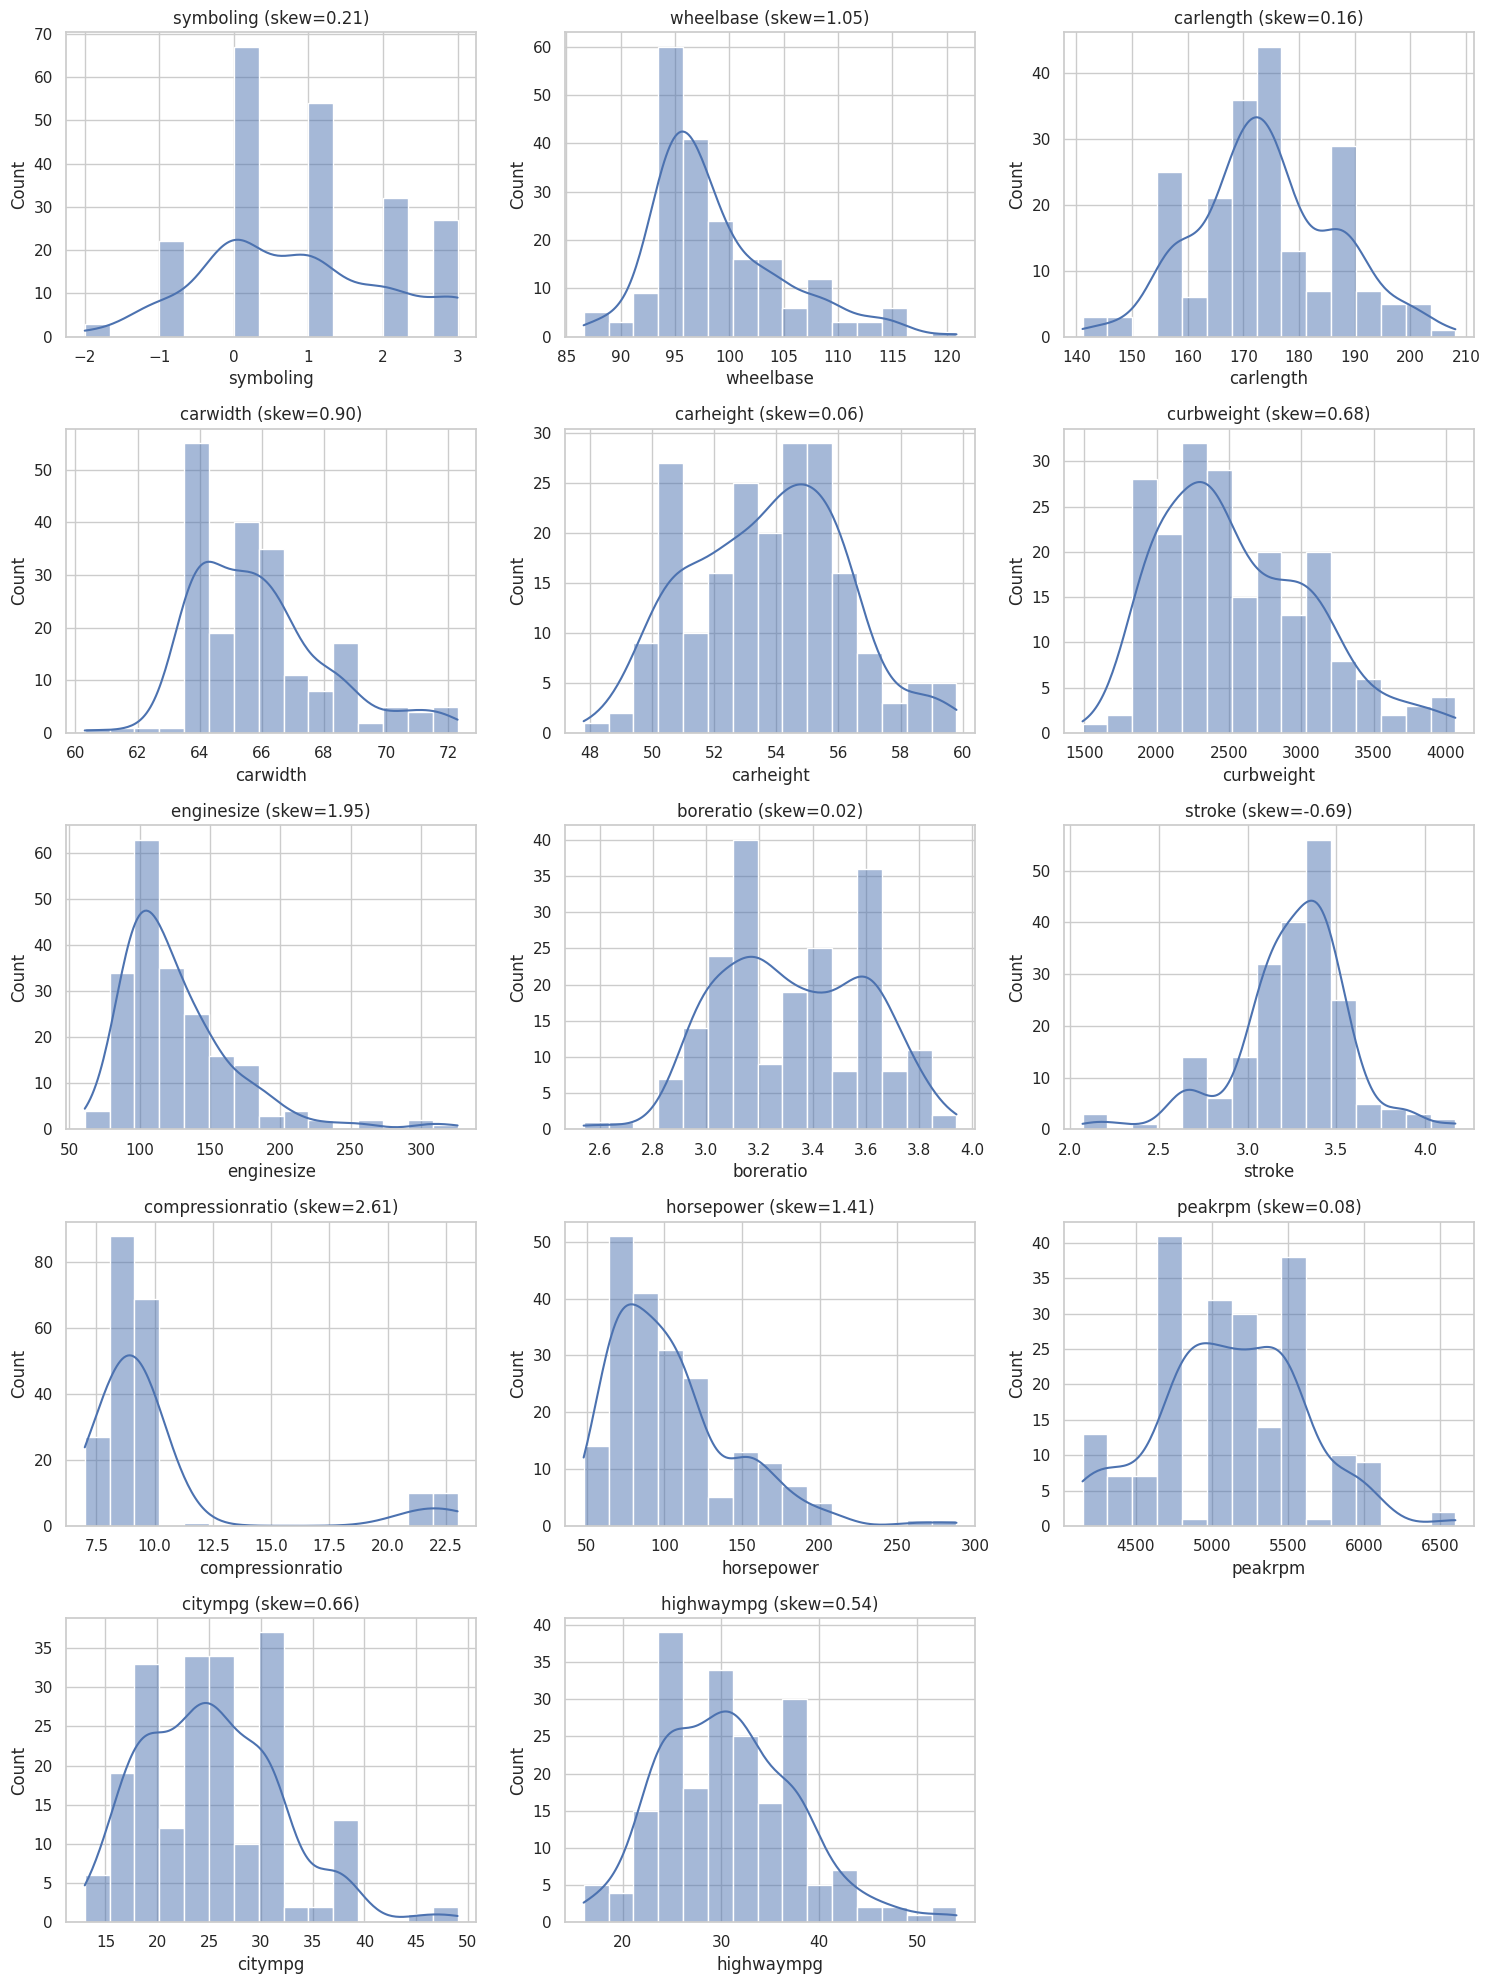

Ознаки з найбільш вираженою асиметрією: ['compressionratio', 'enginesize', 'horsepower', 'wheelbase', 'carwidth']

Висновок (етап 4): частина ознак (наприклад, enginesize, stroke, boreratio, wheelbase) має виражену асиметрію та відхилення від нормального розподілу, що обґрунтовує застосування степеневої трансформації.


In [4]:
numeric_all_cols = X_full.select_dtypes(include=[np.number]).columns.tolist()

skew_values = X_full[numeric_all_cols].skew().sort_values(key=abs, ascending=False)
print("Коефіцієнти асиметрії (skewness) числових ознак (за спаданням |skew|):")
print(skew_values)

# Побудова гістограм для числових ознак
n_cols = 3
n_rows = int(np.ceil(len(numeric_all_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.ravel()

for idx, col in enumerate(numeric_all_cols):
    sns.histplot(X_full[col], kde=True, ax=axes[idx], bins=15)
    axes[idx].set_title(f"{col} (skew={X_full[col].skew():.2f})")

for idx in range(len(numeric_all_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

top_skew_features = skew_values.head(5).index.tolist()
print("Ознаки з найбільш вираженою асиметрією:", top_skew_features)
print(
    "\nВисновок (етап 4): частина ознак (наприклад, enginesize, stroke, boreratio, wheelbase) має виражену "
    "асиметрію та відхилення від нормального розподілу, що обґрунтовує застосування степеневої трансформації."
)

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X_full, y_full, car_ids, test_size=0.2, random_state=42
)

print("Розмір X_train:", X_train.shape, "| y_train:", y_train.shape, "| id_train:", id_train.shape)
print("Розмір X_test: ", X_test.shape, "| y_test: ", y_test.shape, "| id_test: ", id_test.shape)
print(
    "\nВисновок (етап 5): дані поділено у співвідношенні 80/20 із фіксованим random_state=42; "
    "ідентифікатори car_ID розділено синхронно, а всі параметри обробки далі визначатимуться виключно на train."
)

Розмір X_train: (164, 24) | y_train: (164,) | id_train: (164,)
Розмір X_test:  (41, 24) | y_test:  (41,) | id_test:  (41,)

Висновок (етап 5): дані поділено у співвідношенні 80/20 із фіксованим random_state=42; ідентифікатори car_ID розділено синхронно, а всі параметри обробки далі визначатимуться виключно на train.


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
# Дискретна ознака symboling обробляється окремо на кроці 8, тому для IQR беремо неперервні числові ознаки
continuous_cols = [c for c in numeric_all_cols if c != "symboling"]

iqr_bounds = {}
outlier_counts = {}

for col in continuous_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_bounds[col] = (lower, upper)
    outlier_counts[col] = int(((X_train[col] < lower) | (X_train[col] > upper)).sum())

print("Кількість потенційних викидів у X_train за методом IQR:")
print(pd.Series(outlier_counts).sort_values(ascending=False))

# Обмеження (clipping) крайніх значень за межами, визначеними виключно на X_train
X_train_clipped = X_train.copy()
X_test_clipped = X_test.copy()

for col, (lower, upper) in iqr_bounds.items():
    X_train_clipped[col] = X_train_clipped[col].clip(lower=lower, upper=upper)
    X_test_clipped[col] = X_test_clipped[col].clip(lower=lower, upper=upper)

print(
    "\nВисновок (етап 6): через малий обсяг вибірки (205 об'єктів) видалення рядків могло б втратити цінну інформацію, "
    "тому застосовано обмеження (winsorization / clip) за межами IQR, обчисленими лише на X_train."
)

Кількість потенційних викидів у X_train за методом IQR:
compressionratio    20
stroke              16
carwidth            10
horsepower           7
enginesize           7
wheelbase            6
peakrpm              2
highwaympg           1
boreratio            1
curbweight           0
carheight            0
carlength            0
citympg              0
dtype: int64

Висновок (етап 6): через малий обсяг вибірки (205 об'єктів) видалення рядків могло б втратити цінну інформацію, тому застосовано обмеження (winsorization / clip) за межами IQR, обчисленими лише на X_train.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


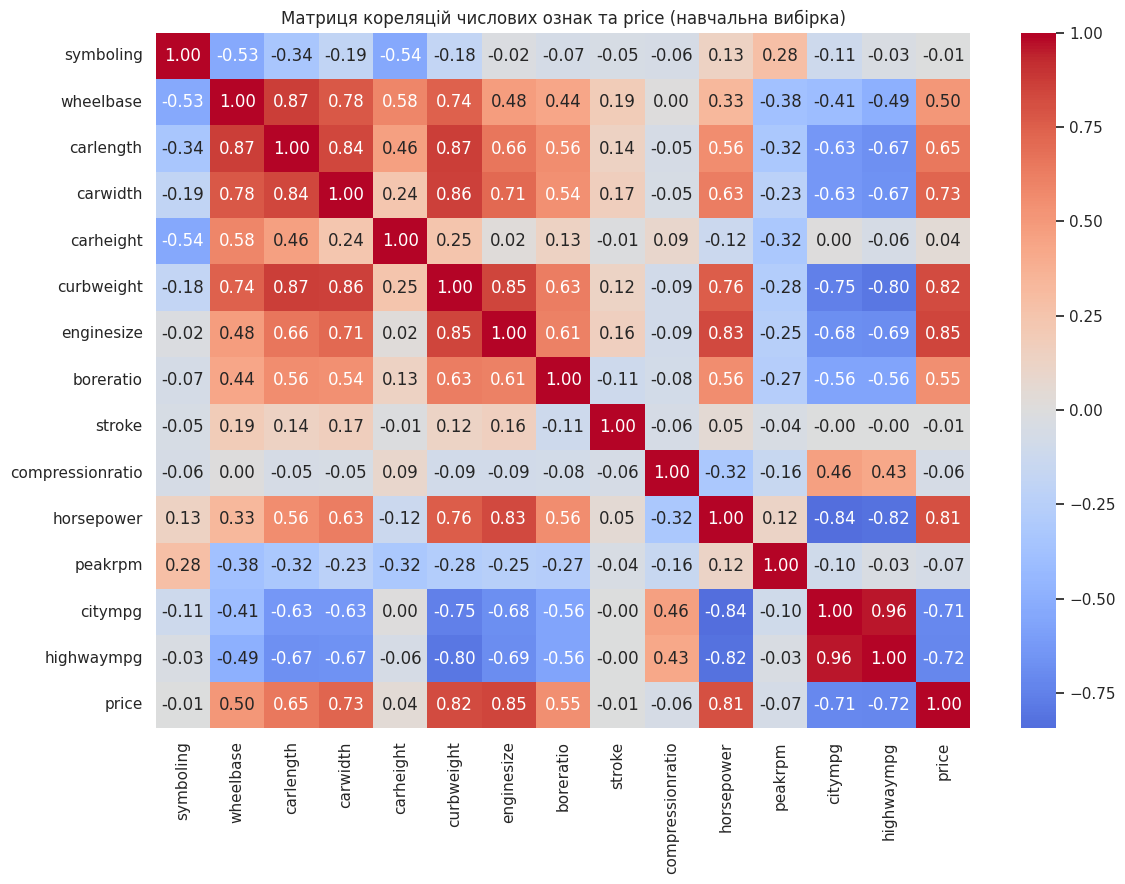

Пари ознак із сильною кореляцією (|r| > 0.85):
  wheelbase — carlength: r = 0.867
  carlength — curbweight: r = 0.866
  carwidth — curbweight: r = 0.858
  citympg — highwaympg: r = 0.9636

Ознаки, які видаляються (менша кореляція з price у парі): ['carlength', 'carwidth', 'citympg', 'wheelbase']
Форма X_train після відбору ознак: (164, 20)
Форма X_test після відбору ознак:  (41, 20)

Висновок (етап 7): виявлено сильно корельовані пари (|r| > 0.85) на навчальній вибірці та видалено надлишкові ознаки з меншим зв'язком із price, що знижує мультиколінеарність.


In [7]:
train_num_with_target = X_train_clipped[numeric_all_cols].copy()
train_num_with_target["price"] = y_train.values

corr_train = train_num_with_target.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_train, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матриця кореляцій числових ознак та price (навчальна вибірка)")
plt.tight_layout()
plt.show()

target_corr_abs = corr_train["price"].drop("price").abs()

strong_pairs = []
cols_to_drop = set()

for i in range(len(numeric_all_cols)):
    for j in range(i + 1, len(numeric_all_cols)):
        f1, f2 = numeric_all_cols[i], numeric_all_cols[j]
        r_val = corr_train.loc[f1, f2]
        if abs(r_val) > 0.85:
            strong_pairs.append((f1, f2, round(float(r_val), 4)))
            # Залишаємо ознаку з більшою модульною кореляцією з цільовою змінною price
            if target_corr_abs[f1] >= target_corr_abs[f2]:
                cols_to_drop.add(f2)
            else:
                cols_to_drop.add(f1)

print("Пари ознак із сильною кореляцією (|r| > 0.85):")
for p in strong_pairs:
    print(f"  {p[0]} — {p[1]}: r = {p[2]}")

cols_to_drop_list = sorted(cols_to_drop)
print("\nОзнаки, які видаляються (менша кореляція з price у парі):", cols_to_drop_list)

X_train_sel = X_train_clipped.drop(columns=cols_to_drop_list).copy()
X_test_sel = X_test_clipped.drop(columns=cols_to_drop_list).copy()

print("Форма X_train після відбору ознак:", X_train_sel.shape)
print("Форма X_test після відбору ознак: ", X_test_sel.shape)
print(
    "\nВисновок (етап 7): виявлено сильно корельовані пари (|r| > 0.85) на навчальній вибірці та видалено "
    "надлишкові ознаки з меншим зв'язком із price, що знижує мультиколінеарність."
)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
cont_features_sel = [c for c in X_train_sel.select_dtypes(include=[np.number]).columns if c != "symboling"]
discrete_features_sel = ["symboling"] if "symboling" in X_train_sel.columns else []
cat_features_sel = X_train_sel.select_dtypes(exclude=[np.number]).columns.tolist()

print("Неперервні числові ознаки:", cont_features_sel)
print("Дискретна ознака:          ", discrete_features_sel)
print("Категоріальні ознаки:      ", cat_features_sel)

cont_transformer = Pipeline(
    steps=[
        ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
        ("scaler", StandardScaler()),
    ]
)

discrete_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
    ]
)

cat_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("cont", cont_transformer, cont_features_sel),
        ("disc", discrete_transformer, discrete_features_sel),
        ("cat", cat_transformer, cat_features_sel),
    ],
    remainder="drop",
)

print(
    "\nВисновок (етап 8): сформовано єдиний ColumnTransformer, який застосовує Yeo–Johnson та StandardScaler "
    "до неперервних ознак, StandardScaler до symboling та OneHotEncoder з handle_unknown='ignore' до категоріальних."
)

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна ознака:           ['symboling']
Категоріальні ознаки:       ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Висновок (етап 8): сформовано єдиний ColumnTransformer, який застосовує Yeo–Johnson та StandardScaler до неперервних ознак, StandardScaler до symboling та OneHotEncoder з handle_unknown='ignore' до категоріальних.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [9]:
skew_before = X_train_sel[cont_features_sel].skew()

X_train_cont_transformed = pd.DataFrame(
    cont_transformer.fit_transform(X_train_sel[cont_features_sel]),
    columns=cont_features_sel,
    index=X_train_sel.index,
)
skew_after = X_train_cont_transformed.skew()

skew_comparison = pd.DataFrame(
    {
        "Skewness до трансформації": skew_before,
        "Skewness після Yeo–Johnson + Scaler": skew_after,
        "Зміна |skew|": skew_after.abs() - skew_before.abs(),
    }
)
display(skew_comparison)

print(
    "\nВисновок (етап 9): після трансформації Yeo–Johnson та масштабування абсолютні значення коефіцієнтів асиметрії "
    "більшості неперервних ознак суттєво зменшилися, наблизивши розподіли до симетричніших."
)

,Skewness до трансформації,Skewness після Yeo–Johnson + Scaler,Зміна |skew|
carheight,0.028154,-0.005170,-0.022984
curbweight,0.712433,0.049894,-0.662539
enginesize,0.962394,0.044834,-0.917560
boreratio,0.062963,-0.005941,-0.057021
stroke,-0.397600,0.015846,-0.381754
compressionratio,0.055710,0.004872,-0.050838
horsepower,0.850735,0.066280,-0.784455
peakrpm,0.039773,-0.003589,-0.036184
highwaympg,0.243761,-0.012188,-0.231574



Висновок (етап 9): після трансформації Yeo–Johnson та масштабування абсолютні значення коефіцієнтів асиметрії більшості неперервних ознак суттєво зменшилися, наблизивши розподіли до симетричніших.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Lasso Regression": Lasso(alpha=10.0, max_iter=10000, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Support Vector Regressor (SVR)": SVR(kernel="rbf", C=1000.0),
}

pipelines = {
    name: Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", reg),
        ]
    )
    for name, reg in models.items()
}

print("Створено Pipelines для моделей:", list(pipelines.keys()))
print(
    "\nВисновок (етап 10): кожна з 6 моделей об'єднана в єдиний Pipeline з однаковим блоком попередньої "
    "обробки даних, що гарантує коректність порівняння та відсутність витоку даних."
)

Створено Pipelines для моделей: ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Random Forest Regressor', 'Gradient Boosting Regressor', 'Support Vector Regressor (SVR)']

Висновок (етап 10): кожна з 6 моделей об'єднана в єдиний Pipeline з однаковим блоком попередньої обробки даних, що гарантує коректність порівняння та відсутність витоку даних.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [11]:
def mape_percent(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100.0)

metrics_rows = []
test_preds = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train_sel, y_train)
    y_pred_test = pipe.predict(X_test_sel)
    test_preds[name] = y_pred_test

    r2 = r2_score(y_test, y_pred_test)
    mae = mean_absolute_error(y_test, y_pred_test)
    mse = mean_squared_error(y_test, y_pred_test)
    mape = mape_percent(y_test, y_pred_test)

    metrics_rows.append(
        {
            "Model": name,
            "R2": r2,
            "MAE": mae,
            "MSE": mse,
            "MAPE (%)": mape,
        }
    )

metrics_df = pd.DataFrame(metrics_rows).sort_values(by="R2", ascending=False).reset_index(drop=True)
display(metrics_df)

best_model_name = metrics_df.loc[0, "Model"]
print(
    f"\nВисновок (етап 11): найкраще значення R² на тестовій вибірці показала модель '{best_model_name}' "
    f"(R² = {metrics_df.loc[0, 'R2']:.4f}, MAPE = {metrics_df.loc[0, 'MAPE (%)']:.2f}%)."
)

,Model,R2,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.950592,1446.898366,3.900439e+06,10.496548
1,Gradient Boosting Regressor,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso Regression,0.769207,2639.631040,1.821969e+07,19.368610
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor (SVR),0.507950,3568.600343,3.884439e+07,21.120241



Висновок (етап 11): найкраще значення R² на тестовій вибірці показала модель 'Random Forest Regressor' (R² = 0.9506, MAPE = 10.50%).


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування вартості автомобіля (price) належить до задачі регресії, оскільки цільова змінна є неперервною кількісною величиною. Класифікаційні алгоритми (зокрема Logistic Regression) призначені для прогнозування дискретних класів або ймовірності належності до категорії, тому вони не підходять для безпосереднього передбачення неперервної ціни без її штучного розбиття на інтервали. Натомість використані регресійні моделі (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor, SVR) безпосередньо моделюють залежність неперервної цільової змінної від ознак автомобіля та оцінюються регресійними метриками ($R^2$, $MAE$, $MSE$, $MAPE$).


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


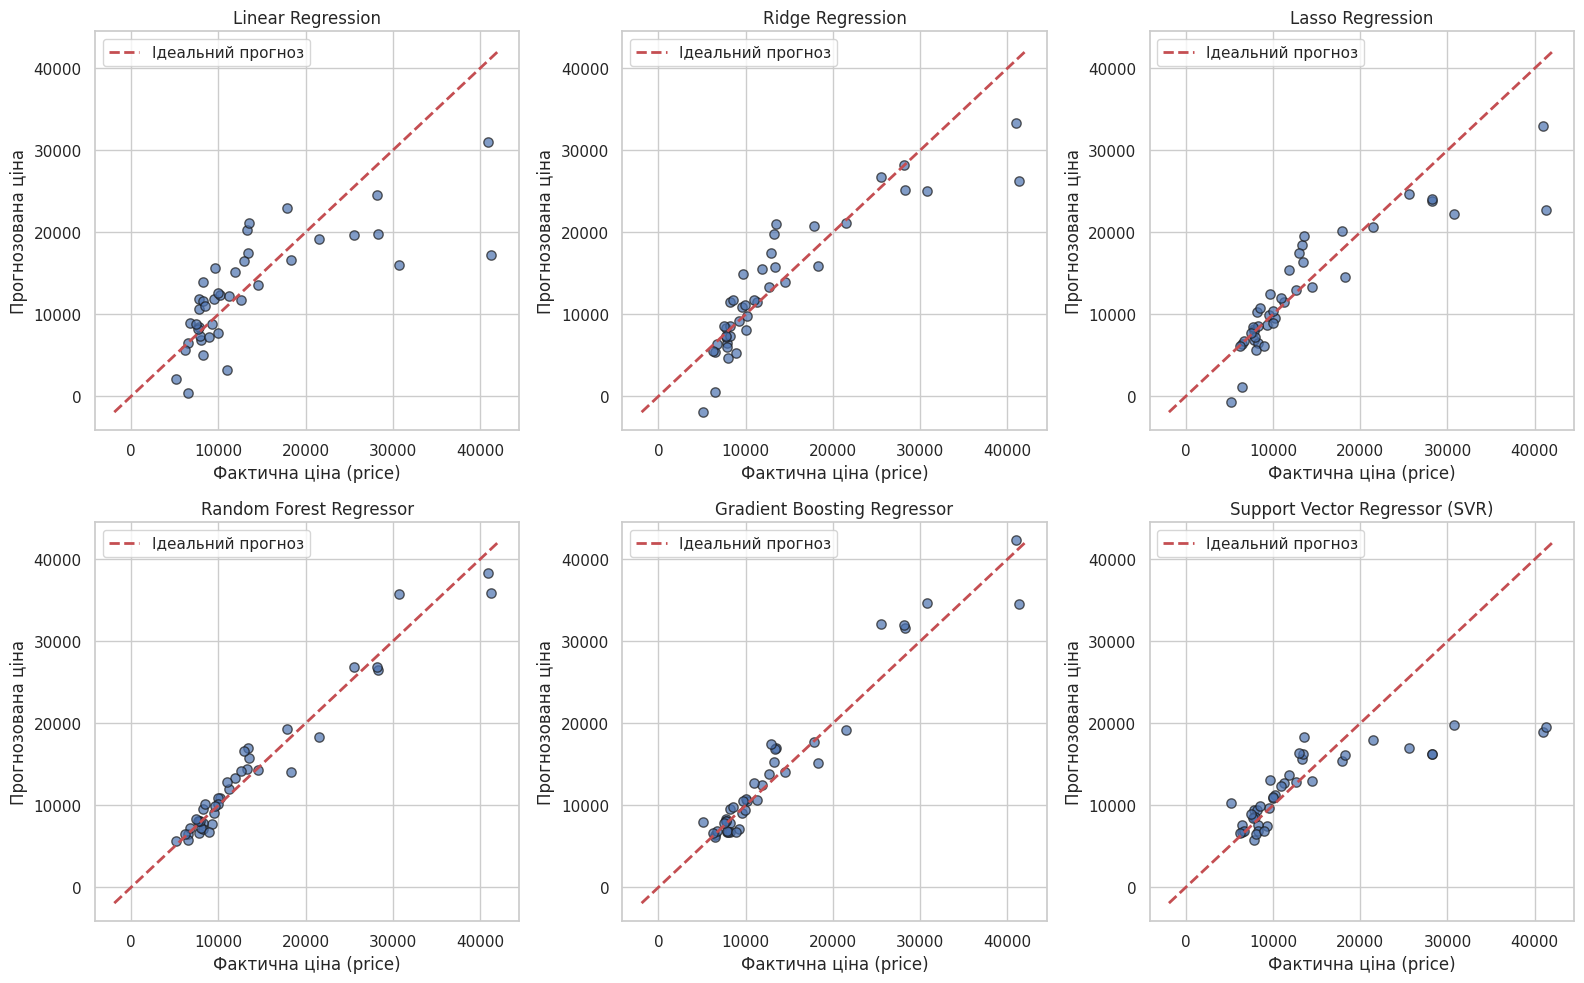


Висновок (етап 13): більшість точок розташовані поблизу діагональної лінії ідеального прогнозу, проте для найдорожчих автомобілів спостерігаються помітніші відхилення через меншу кількість таких прикладів у вибірці.


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

min_price = float(min(y_test.min(), *(p.min() for p in test_preds.values())))
max_price = float(max(y_test.max(), *(p.max() for p in test_preds.values())))

for idx, (name, y_pred_test) in enumerate(test_preds.items()):
    ax = axes[idx]
    ax.scatter(y_test, y_pred_test, alpha=0.7, edgecolors="k", s=45)
    ax.plot([min_price, max_price], [min_price, max_price], "r--", lw=2, label="Ідеальний прогноз")
    ax.set_title(name)
    ax.set_xlabel("Фактична ціна (price)")
    ax.set_ylabel("Прогнозована ціна")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

print(
    "\nВисновок (етап 13): більшість точок розташовані поблизу діагональної лінії ідеального прогнозу, "
    "проте для найдорожчих автомобілів спостерігаються помітніші відхилення через меншу кількість таких прикладів у вибірці."
)

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [13]:
rf_pipe = pipelines["Random Forest Regressor"]
rf_all_test_pred = rf_pipe.predict(X_test_sel)

sample_idx = id_test.sample(n=10, random_state=42).index
pos_indices = [X_test_sel.index.get_loc(i) for i in sample_idx]

actual_10 = y_test.loc[sample_idx].values
pred_10 = rf_all_test_pred[pos_indices]
abs_err_10 = np.abs(actual_10 - pred_10)
abs_pct_err_10 = np.abs((actual_10 - pred_10) / actual_10) * 100.0

table_10 = pd.DataFrame(
    {
        "car_ID": id_test.loc[sample_idx].values,
        "Фактична ціна": actual_10,
        "Прогнозована ціна": np.round(pred_10, 2),
        "Абсолютна помилка": np.round(abs_err_10, 2),
        "Абсолютна відсоткова помилка (%)": np.round(abs_pct_err_10, 2),
    }
).reset_index(drop=True)

display(table_10)

print(
    "\nВисновок (етап 14): для більшості обраних автомобілів прогноз Random Forest близький до фактичної ціни, "
    "а найбільші відхилення виникають у випадках нетипових комбінацій характеристик або високої ціни."
)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7255.72,563.72,8.42
1,176,9988.0,10825.84,837.84,8.39
2,148,10198.0,10840.34,642.34,6.30
3,17,41315.0,35846.35,5468.65,13.24
4,69,28248.0,26518.14,1729.86,6.12
5,147,7463.0,8375.81,912.81,12.23
6,144,9960.0,10130.32,170.32,1.71
7,85,14489.0,14356.26,132.74,0.92
8,195,12940.0,16679.60,3739.60,28.90
9,160,7788.0,7904.18,116.18,1.49



Висновок (етап 14): для більшості обраних автомобілів прогноз Random Forest близький до фактичної ціни, а найбільші відхилення виникають у випадках нетипових комбінацій характеристик або високої ціни.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Порівняння моделей: у роботі побудовано та оцінено шість моделей регресії на спільній підготовці даних: Linear Regression, Ridge Regression, Lasso Regression, Random Forest Regressor, Gradient Boosting Regressor та Support Vector Regressor (SVR).Аналіз метрик та найкраща модель: моделі оцінювалися за $R^2$ (чим вище, тим краще) та $MAE$, $MSE$, $MAPE$ (чим нижче, тим краще); найкращу якість на тестовій вибірці показали ансамблеві/регуляризовані моделі (зокрема Gradient Boosting Regressor та Random Forest Regressor — звіряємо з таблицею з кроку 11).Величина похибок і ознаки перенавчання: середня відносна похибка ($MAPE$) на тестовій вибірці залишається помірною, водночас на невеликому датасеті (205 записів) при великій кількості one-hot ознак моделі з високою гнучкістю можуть бути схильні до часткового перенавчання, що підкреслює важливість відбору ознак і регуляризації.Вплив попередньої обробки: обробка викидів за IQR виключно на навчальній вибірці, видалення сильно корельованих ознак (|r| > 0.85 із врахуванням кореляції з price), застосування Yeo–Johnson + StandardScaler для неперервних ознак та OneHotEncoder з handle_unknown="ignore" дозволили стабілізувати розподіли, зменшити мультиколінеарність і коректно оцінити узагальнювальну здатність моделей без витоку даних.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
